# Mini-project 2: Reliability of a Stay Cable in a Cable-Stayed Bridge

**Student Name:** Amilcar Diaz

**CCID:** adiazgar

## Summary

This notebook evaluates the reliability of a stay cable of a cable-stayed bridge in Alberta. The permanent tension of the cable is estimated from acceleration measurements using the taut-string (vibration) method, and the uncertainty in the cable properties and in the measured frequency is propagated to the tension and to a limit state function. The reliability index and the probability of failure are computed with the First-Order Second-Moment (FOSM) method and verified with Monte Carlo simulation.

## 1. Problem description

Stay cables carry the deck loads of a cable-stayed bridge to the pylons, so their tension is one of the most important quantities to monitor. If the tension is too high, the cable may approach its capacity; if it changes over time, it may indicate damage, loss of anchorage or changes in the structure.

A common and inexpensive way to estimate the tension of a cable in service is the **vibration method**:

1. An accelerometer is attached to the cable and records its ambient vibration (in this example, records of 200 s sampled at 50 Hz).
2. The Fast Fourier Transform (FFT) of the record is computed, and the fundamental frequency $f_1$ is obtained by averaging the five highest peaks.
3. The tension is computed with the taut-string formula, which relates the tension to the frequency, the mass per unit length and the length of the cable.

## 2. Basic random variables

The cable is made of 37 strands of 15.7 mm, grade 1860 MPa (ASTM A416-16), with a minimum breaking strength of 279 kN per strand.

| Variable | Mean | CV | Distribution | Justification |
|---|---|---|---|---|
| $R$, resistance | 37 × 279 kN = 10 323 kN | 0.015 | Normal | Ali, Katsuchi and Yamada (2018); Nowak (1999) |
| $m$, total mass per unit length | 54 kg/m | 0.02 | Normal | Manufacturing tolerances (assumed) |
| $L$, effective length | 150 m | 0.03 | Normal | Uncertainty due to dampers and anchorages (assumed) |
| $f_1$, fundamental frequency ($n$ = 1) | 0.96 Hz | 0.01 | Normal | Hypothetical measurement; resolution, noise, temperature |
| $T_{LL}$, live load | 1.18 × 1000 kN = 1180 kN | 0.18 | Lognormal | Pushka et al. (2022); Kulicki et al. (2007) |

**Live load:** the nominal CL-800 live load produces a nominal tension in the analyzed cable equal to $T_{LL,n}$ = 1000 kN. This value depends on the geometry and properties of the bridge and on the position of the cable, and it is assumed for this example.

**Independence:** the variables are assumed to be statistically independent because they come from different sources, so the FOSM variance does not include covariance terms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Resistance R (kN): 37 strands of 15.7 mm, grade 1860 MPa (ASTM A416-16)
n_strands = 37
R_strand = 279.0
mu_R = n_strands * R_strand
cv_R = 0.015
sigma_R = cv_R * mu_R

# Total mass per unit length m (kg/m)
mu_m = 54.0
cv_m = 0.02
sigma_m = cv_m * mu_m

# Effective length L (m)
mu_L = 150.0
cv_L = 0.03
sigma_L = cv_L * mu_L

# Fundamental frequency f1 (Hz)
n = 1
mu_f = 0.96
cv_f = 0.01
sigma_f = cv_f * mu_f

print(f"R:  mean = {mu_R:.1f} kN, std = {sigma_R:.1f} kN")
print(f"m:  mean = {mu_m:.2f} kg/m, std = {sigma_m:.3f} kg/m")
print(f"L:  mean = {mu_L:.1f} m, std = {sigma_L:.2f} m")
print(f"f1: mean = {mu_f:.3f} Hz, std = {sigma_f:.4f} Hz")

R:  mean = 10323.0 kN, std = 154.8 kN
m:  mean = 54.00 kg/m, std = 1.080 kg/m
L:  mean = 150.0 m, std = 4.50 m
f1: mean = 0.960 Hz, std = 0.0096 Hz


In [2]:
# Live load T_LL (kN): lognormal, bias = 1.18, CV = 0.18
T_LL_nominal = 1000.0   # nominal tension produced by the CL-800 load in the analyzed cable (assumed)
bias_LL = 1.18
cv_LL = 0.18

mu_LL = bias_LL * T_LL_nominal
sigma_LL = cv_LL * mu_LL

# Parameters of the underlying normal distribution of ln(T_LL)
zeta_LL = np.sqrt(np.log(1 + cv_LL**2))
lambda_LL = np.log(mu_LL) - zeta_LL**2 / 2

print(f"T_LL: nominal = {T_LL_nominal:.1f} kN, mean = {mu_LL:.1f} kN, std = {sigma_LL:.1f} kN")
print(f"      lambda = {lambda_LL:.4f}, zeta = {zeta_LL:.4f}")

T_LL: nominal = 1000.0 kN, mean = 1180.0 kN, std = 212.4 kN
      lambda = 7.0573, zeta = 0.1786


## 3. Quantities of interest

**Permanent tension** (taut-string formula, in N when $m$ is in kg/m, $L$ in m and $f_n$ in Hz):

$$T_{med} = 4\,m\,L^2\left(\frac{f_n}{n}\right)^2 \tag{1}$$

**Limit state function** (failure if $g < 0$):

$$g = R - \left[\,4\,m\,L^2\left(\frac{f_n}{n}\right)^2 + T_{LL}\right] \tag{2}$$

## 4. Probabilistic analysis

### 4.1 FOSM: mean and standard deviation of $T_{med}$ and $g$

The function is linearized at the mean values. The partial derivatives of $T_{med}$ (with $n = 1$) are:

$$\frac{\partial T_{med}}{\partial m} = 4L^2f^2 \tag{3}$$

$$\frac{\partial T_{med}}{\partial L} = 8\,m\,L\,f^2 \tag{4}$$

$$\frac{\partial T_{med}}{\partial f} = 8\,m\,L^2f \tag{5}$$

and for $g$:

$$\frac{\partial g}{\partial R} = 1, \qquad \frac{\partial g}{\partial T_{LL}} = -1, \qquad \frac{\partial g}{\partial x_i} = -\frac{\partial T_{med}}{\partial x_i} \;\; \text{for } m,\ L \text{ and } f \tag{6}$$

Since the variables are independent, the variance has no covariance terms:

$$\sigma_g^2 \approx \sum_i \left(\frac{\partial g}{\partial x_i}\right)^2 \sigma_{X_i}^2 \tag{7}$$

In [3]:
# FOSM for the permanent tension T_med (kN), evaluated at the mean values
mu_T = 4 * mu_m * mu_L**2 * (mu_f / n)**2 / 1000

dT_dm = 4 * mu_L**2 * (mu_f / n)**2 / 1000
dT_dL = 8 * mu_m * mu_L * (mu_f / n)**2 / 1000
dT_df = 8 * mu_m * mu_L**2 * mu_f / n**2 / 1000

var_T_m = (dT_dm * sigma_m)**2
var_T_L = (dT_dL * sigma_L)**2
var_T_f = (dT_df * sigma_f)**2
sigma_T = np.sqrt(var_T_m + var_T_L + var_T_f)

print(f"T_med: mean = {mu_T:.1f} kN, std = {sigma_T:.1f} kN, CV = {sigma_T / mu_T:.4f}")
print(f"T_med / mean resistance = {mu_T / mu_R:.3f}")
print("Contribution to the variance of T_med:")
print(f"   m: {var_T_m / sigma_T**2 * 100:.1f} %")
print(f"   L: {var_T_L / sigma_T**2 * 100:.1f} %")
print(f"   f: {var_T_f / sigma_T**2 * 100:.1f} %")

T_med: mean = 4479.0 kN, std = 297.1 kN, CV = 0.0663
T_med / mean resistance = 0.434
Contribution to the variance of T_med:
   m: 9.1 %
   L: 81.8 %
   f: 9.1 %


In [4]:
# FOSM for the limit state function g (kN)
mu_g = mu_R - mu_T - mu_LL

dg_dR = 1
dg_dm = -dT_dm
dg_dL = -dT_dL
dg_df = -dT_df
dg_dLL = -1

sigma_g = np.sqrt((dg_dR * sigma_R)**2 + (dg_dm * sigma_m)**2 + (dg_dL * sigma_L)**2
                  + (dg_df * sigma_f)**2 + (dg_dLL * sigma_LL)**2)

print(f"g: mean = {mu_g:.1f} kN, std = {sigma_g:.1f} kN")

g: mean = 4664.0 kN, std = 396.7 kN


### 4.2 Reliability index and probability of failure

$$\beta = \frac{\mu_g}{\sigma_g} \tag{8}$$

$$P_f = \Phi(-\beta) \tag{9}$$

The result is compared with the target reliability index $\beta_T = 3.5$ (AASHTO LRFD, 75-year service life). A higher value could be required for stay cables.

In [5]:
beta_fosm = mu_g / sigma_g
Pf_fosm = norm.cdf(-beta_fosm)
beta_T = 3.5

print(f"FOSM: beta = {beta_fosm:.3f}, Pf = {Pf_fosm:.3e}")
print(f"Target: beta_T = {beta_T}")

FOSM: beta = 11.757, Pf = 3.233e-32
Target: beta_T = 3.5


### 4.3 Monte Carlo simulation

FOSM linearizes a nonlinear function ($L$ and $f$ appear squared) and assumes that $g$ is normal (while $T_{LL}$ is lognormal); Monte Carlo simulation is used to verify it.

T_med (Monte Carlo): mean = 4483.9 kN, std = 297.3 kN
T_med (FOSM):        mean = 4479.0 kN, std = 297.1 kN


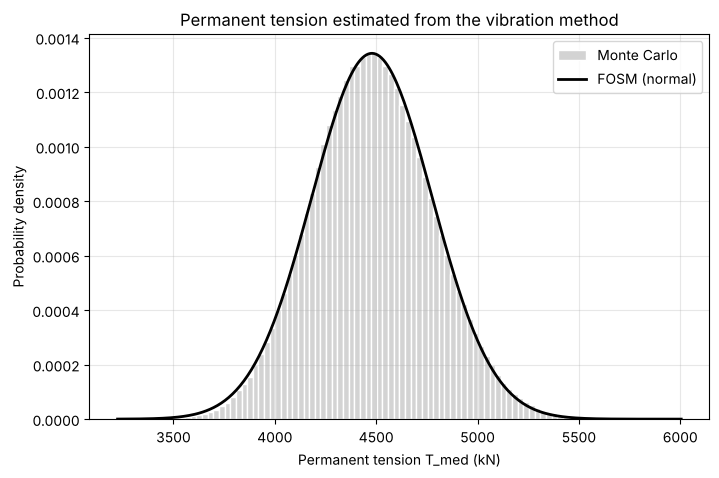

In [6]:
# Monte Carlo samples of the basic random variables
N = 1_000_000
rng = np.random.default_rng(42)

R_s = rng.normal(mu_R, sigma_R, N)
m_s = rng.normal(mu_m, sigma_m, N)
L_s = rng.normal(mu_L, sigma_L, N)
f_s = rng.normal(mu_f, sigma_f, N)

# Permanent tension (kN)
T_s = 4 * m_s * L_s**2 * (f_s / n)**2 / 1000

print(f"T_med (Monte Carlo): mean = {T_s.mean():.1f} kN, std = {T_s.std():.1f} kN")
print(f"T_med (FOSM):        mean = {mu_T:.1f} kN, std = {sigma_T:.1f} kN")

# Histogram of T_med with the FOSM normal approximation
T_line = np.linspace(T_s.min(), T_s.max(), 300)

plt.figure(figsize=(8, 5))
plt.hist(T_s, bins=100, density=True, color="lightgray", edgecolor="white", label="Monte Carlo")
plt.plot(T_line, norm.pdf(T_line, mu_T, sigma_T), color="black", linewidth=2, label="FOSM (normal)")
plt.xlabel("Permanent tension T_med (kN)")
plt.ylabel("Probability density")
plt.title("Permanent tension estimated from the vibration method")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

g (Monte Carlo): mean = 4658.9 kN, std = 397.0 kN, beta = 11.737
g (FOSM):        mean = 4664.0 kN, std = 396.7 kN, beta = 11.757

Pf FOSM        = 3.233e-32
Pf Monte Carlo < 1e-06  (0 failures in 1000000 samples)


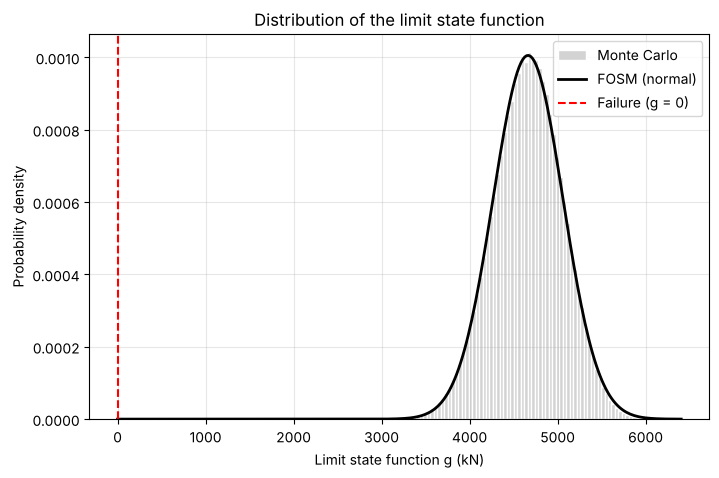

In [7]:
# Live load samples (lognormal)
LL_s = rng.lognormal(lambda_LL, zeta_LL, N)

# Limit state function (kN)
g_s = R_s - T_s - LL_s

n_fail = np.sum(g_s < 0)
Pf_mc = n_fail / N
beta_mc = g_s.mean() / g_s.std()

print(f"g (Monte Carlo): mean = {g_s.mean():.1f} kN, std = {g_s.std():.1f} kN, beta = {beta_mc:.3f}")
print(f"g (FOSM):        mean = {mu_g:.1f} kN, std = {sigma_g:.1f} kN, beta = {beta_fosm:.3f}")
print()
print(f"Pf FOSM        = {Pf_fosm:.3e}")
if n_fail > 0:
    print(f"Pf Monte Carlo = {Pf_mc:.3e}  ({n_fail} failures)")
else:
    print(f"Pf Monte Carlo < {1 / N:.0e}  (0 failures in {N} samples)")

# Histogram of g with the FOSM normal approximation
g_line = np.linspace(min(g_s.min(), 0), g_s.max(), 300)

plt.figure(figsize=(8, 5))
plt.hist(g_s, bins=100, density=True, color="lightgray", edgecolor="white", label="Monte Carlo")
plt.plot(g_line, norm.pdf(g_line, mu_g, sigma_g), color="black", linewidth=2, label="FOSM (normal)")
plt.axvline(0, color="red", linestyle="--", label="Failure (g = 0)")
plt.xlabel("Limit state function g (kN)")
plt.ylabel("Probability density")
plt.title("Distribution of the limit state function")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 4.4 Linear correlation between $g$ and the basic random variables

The correlation coefficients are computed from the Monte Carlo samples.

Correlation with g:
   R    = 0.391
   m    = -0.225
   L    = -0.677
   f1   = -0.226
   T_LL = -0.536


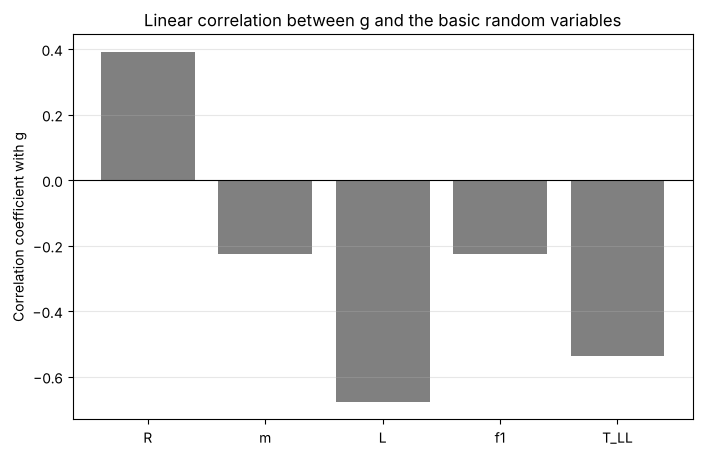

In [8]:
rho_R = np.corrcoef(g_s, R_s)[0, 1]
rho_m = np.corrcoef(g_s, m_s)[0, 1]
rho_L = np.corrcoef(g_s, L_s)[0, 1]
rho_f = np.corrcoef(g_s, f_s)[0, 1]
rho_LL = np.corrcoef(g_s, LL_s)[0, 1]

print("Correlation with g:")
print(f"   R    = {rho_R:.3f}")
print(f"   m    = {rho_m:.3f}")
print(f"   L    = {rho_L:.3f}")
print(f"   f1   = {rho_f:.3f}")
print(f"   T_LL = {rho_LL:.3f}")

plt.figure(figsize=(8, 5))
plt.bar(["R", "m", "L", "f1", "T_LL"], [rho_R, rho_m, rho_L, rho_f, rho_LL], color="gray")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Correlation coefficient with g")
plt.title("Linear correlation between g and the basic random variables")
plt.grid(alpha=0.3, axis="y")
plt.show()

## 5. Research paper summary

**Hou, Sun and Chen (2020).** *Journal of Bridge Engineering*, 25(7). DOI: [10.1061/(ASCE)BE.1943-5592.0001573](https://doi.org/10.1061/(ASCE)BE.1943-5592.0001573)

- The paper uses the same vibration method to estimate cable tensions and the same reliability index used in this notebook.
- **Contribution of the paper:** cable tensions measured during one year of monitoring.
- **Contribution of this example:** propagation of the uncertainty in $m$, $L$ and $f$ to the estimated tension and to the reliability of the cable.

**What I understood:**

*(To be written by the author.)*

**What remains unclear:**

*(To be written by the author.)*

## 6. Assumptions and limitations

- The live load parameters come from another study (calibrated with the HL-93 load model) and are applied to the CL-800 load only for this example.
- The measured frequency and the coefficients of variation of $m$, $L$ and $f$ are illustrative.
- The taut-string formula neglects the bending stiffness of the cable, the sag (catenary effect) and the effect of the dampers.

## 7. References

- Ali, Katsuchi and Yamada (2018). *Journal of Structural Engineering, JSCE*, 64A: 99–108. DOI: 10.11532/structcivil.64A.99
- ASTM A416/A416M-16. *Standard Specification for Low-Relaxation, Seven-Wire Steel Strand for Prestressed Concrete.*
- Hou, Sun and Chen (2020). *Journal of Bridge Engineering*, 25(7). DOI: 10.1061/(ASCE)BE.1943-5592.0001573
- Kulicki et al. (2007). NCHRP 20-7.
- Nowak (1999). NCHRP Report 368.
- Pushka et al. (2022). *Canadian Journal of Civil Engineering*, 49(6): 899–909. DOI: 10.1139/cjce-2021-0031